In [1]:
import pickle
import sys, os
import json
import numpy as np
import torch
import gc
import time
from datasets import load_dataset
import yaml
from pathlib import Path
from typing import Dict
import datetime as dt
from typing import Dict, Optional, Tuple, Type

from torch.utils.data import DataLoader


project_root = os.path.abspath(os.path.join(os.getcwd(),'..'))
print(project_root)
sys.path.append(project_root)

from src.utils.logger import get_logger
logger = get_logger(__name__)

/home/user/anaconda3/envs/lerobot/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/user/project/objectvla


In [2]:
import torch
import torch.nn.functional as F  # noqa: N812
from torch import Tensor, nn
from transformers.models.auto import CONFIG_MAPPING
import lerobot
print(lerobot.__file__)

/home/user/project/objectvla/vlas/lerobot/src/lerobot/__init__.py


In [3]:
from lerobot.policies.pi0.modeling_pi0 import PI0Policy
from lerobot.policies.factory import make_pre_post_processors
model_id = "lerobot/pi0_base"

In [4]:
import os
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
pi0_path = os.path.abspath("../vlas/checkpoints/pi0_base")
print(pi0_path)
# pi0_path = 'lerobot/pi0'
policy = PI0Policy.from_pretrained(pretrained_name_or_path=pi0_path,
                                   local_files_only=True).to(device)

/home/user/project/objectvla/vlas/checkpoints/pi0_base
The PI0 model is a direct port of the OpenPI implementation. 
This implementation follows the original OpenPI structure for compatibility. 
Original implementation: https://github.com/Physical-Intelligence/openpi


Loading model from: /home/user/project/objectvla/vlas/checkpoints/pi0_base
✓ Loaded state dict from model.safetensors
Remapped 777 state dict keys
All keys loaded successfully!


In [5]:
preprocess, postprocess = make_pre_post_processors(
    policy.config,
    model_id,
    preprocessor_overrides={"device_processor": {"device": str(device)}},
)

In [6]:
import tensorflow as tf

from typing import Dict, Any
from PIL import Image

def resize_image(img, resize_size):
    """
    Takes numpy array corresponding to a single image and returns resized image as numpy array.

    NOTE (Moo Jin): To make input images in distribution with respect to the inputs seen at training time, we follow
                    the same resizing scheme used in the Octo dataloader, which OpenVLA uses for training.
    """
    assert isinstance(resize_size, tuple)
    # Resize to image size expected by model
    img = tf.image.encode_jpeg(img)  # Encode as JPEG, as done in RLDS dataset builder
    img = tf.io.decode_image(img, expand_animations=False, dtype=tf.uint8)  # Immediately decode back
    img = tf.image.resize(img, resize_size, method="lanczos3", antialias=True)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)
    img = img.numpy()
    return img

def prepare_observation(
        observation: Dict[str, Any], batch: int = 1
    ) -> Dict[str, Any]:
        for key in observation:
            if key.startswith("observation.images") and isinstance(
                observation[key],
                (np.ndarray, torch.Tensor, Image.Image),
            ):
                print(key, observation[key].shape)
                img_tensor = observation[key].unsqueeze(0).repeat(
                    batch, 1, 1, 1
                )
                observation[key] = img_tensor

        state_tensor = (
            torch.tensor(observation["observation.state"]).unsqueeze(0)
            .float()
            .to(device)
        )
        print("state_tensor:", state_tensor.shape)
        observation["observation.state"] = state_tensor.repeat(batch, 1)

        if isinstance(observation["task"], str):
            observation["task"] = [observation["task"]]
        observation["task"] = observation["task"] * batch
        
        return observation

I0000 00:00:1773371924.235309 2672150 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1773371924.300935 2672150 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1773371926.407776 2672150 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [105]:
from datasets import load_dataset
from PIL import Image
# Login using e.g. `huggingface-cli login` to access this dataset
ds = load_dataset("lerobot/libero_object_image", cache_dir="../mydatasets/amylingchen/libero")
data_index = 5
data = ds["train"][data_index]
task_index = data['task_index']

image_pil = np.array(data['observation.images.image'])  # PIL.Image


image_np = resize_image(image_pil, (224, 224))  # 调整大小到 (224, 224)
image_np = image_np / 255.0  # 归一化到 [0,1]
# 转成 Tensor 并调整通道顺序 (HWC -> CHW)
image_tensor = torch.from_numpy(image_np).permute(2, 0, 1).to(device).float()

wrist_image = np.array(data['observation.images.wrist_image'])
wrist_image_np = resize_image(wrist_image, (224, 224))
wrist_image_np = wrist_image_np / 255.0

wrist_image_tensor = torch.from_numpy(wrist_image_np).permute(2, 0, 1).to(device).float()

print(image_tensor.shape, wrist_image_tensor.shape,image_tensor.dtype,wrist_image_tensor.dtype)

object = 'ketchup'

observation = {
    "observation.state": torch.tensor(data['observation.state']).to(device).float(),
    'observation.images.base_0_rgb': image_tensor,
    'observation.images.left_wrist_0_rgb': wrist_image_tensor,
    # 'observation.images.right_wrist_0_rgb': wrist_image_tensor,
    "task": [f'pick up the {object} and place it in the basket'], 
    # "task": [f'{object}'], 
}

torch.Size([3, 224, 224]) torch.Size([3, 224, 224]) torch.float32 torch.float32


In [106]:
data

{'observation.images.image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=256x256>,
 'observation.images.wrist_image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=256x256>,
 'observation.state': [-0.15244629979133606,
  -0.0002454198547638953,
  0.26688846945762634,
  3.1297802925109863,
  -0.029546024277806282,
  -0.08590351045131683,
  0.03906488046050072,
  -0.03906923905014992],
 'action': [0.23035714030265808,
  0.0,
  -0.0,
  -0.05249999836087227,
  -0.007499999832361937,
  -0.03214285895228386,
  -1.0],
 'timestamp': 0.5,
 'frame_index': 5,
 'episode_index': 0,
 'index': 5,
 'task_index': 0}

In [107]:
observation2 = preprocess(observation)

In [108]:
print(type(observation2))
print(observation2.keys())
for k, v in observation2.items():
    if hasattr(v, "shape"):
        print(k, v.shape, getattr(v, "device", None))
    else:
        print(k, type(v), v)

<class 'dict'>
dict_keys(['action', 'next.reward', 'next.done', 'next.truncated', 'info', 'task', 'observation.state', 'observation.images.base_0_rgb', 'observation.images.left_wrist_0_rgb', 'observation.language.tokens', 'observation.language.attention_mask'])
action <class 'NoneType'> None
next.reward <class 'float'> 0.0
next.done <class 'bool'> False
next.truncated <class 'bool'> False
info <class 'dict'> {}
task <class 'list'> ['pick up the ketchup and place it in the basket\n']
observation.state torch.Size([1, 8]) cuda:1
observation.images.base_0_rgb torch.Size([1, 3, 224, 224]) cuda:1
observation.images.left_wrist_0_rgb torch.Size([1, 3, 224, 224]) cuda:1
observation.language.tokens torch.Size([1, 48]) cuda:1
observation.language.attention_mask torch.Size([1, 48]) cuda:1


In [109]:
observation2['observation.language.tokens'],observation2['observation.language.attention_mask'],observation2['task']

(tensor([[     2,  18075,    908,    573, 104487,    578,   2040,    665,    575,
             573,  12220,    108,      0,      0,      0,      0,      0,      0,
               0,      0,      0,      0,      0,      0,      0,      0,      0,
               0,      0,      0,      0,      0,      0,      0,      0,      0,
               0,      0,      0,      0,      0,      0,      0,      0,      0,
               0,      0,      0]], device='cuda:1'),
 tensor([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False]],
        device='cuda:1'),
 ['pick up the ketchup and place it in the basket\n'])

In [ ]:
actions, input_attentions,action_attentions = policy.predict_action_chunk(observation2, output_attentions=True)

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


In [111]:
actions

tensor([[[-2.3492e-01,  3.9338e-01, -1.6936e+00,  ..., -1.0689e-03,
          -4.3731e-04, -2.8439e-04],
         [-2.3037e-01,  3.6771e-01, -1.7150e+00,  ..., -5.9090e-04,
           2.9769e-05, -1.4964e-04],
         [-2.2795e-01,  3.4034e-01, -1.7401e+00,  ..., -4.7263e-04,
          -4.4733e-04, -6.2885e-05],
         ...,
         [ 6.6846e-03,  3.0198e-02, -2.3958e-01,  ...,  6.0983e-04,
           5.5571e-04, -7.0574e-04],
         [ 2.0397e-02, -1.5513e-02, -1.6776e-01,  ..., -6.6327e-04,
           3.3735e-04,  3.8671e-04],
         [ 3.7551e-02, -6.1537e-02, -9.1824e-02,  ...,  5.0999e-06,
          -2.2908e-04,  6.9071e-04]]], device='cuda:1')

In [112]:
actions.shape

torch.Size([1, 50, 32])

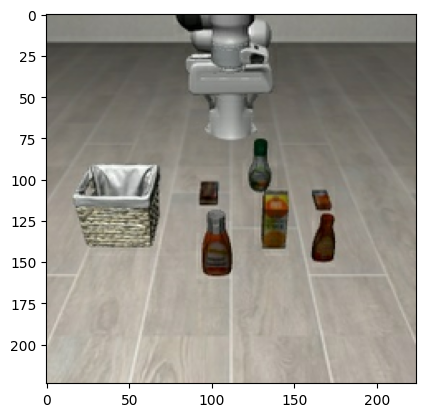

In [125]:
import matplotlib.pyplot as plt
plt.imshow(image_np)

(tensor(0.7312, device='cuda:1', dtype=torch.float64),
 tensor(0., device='cuda:1', dtype=torch.float64),
 torch.Size([1, 8, 816, 816]))

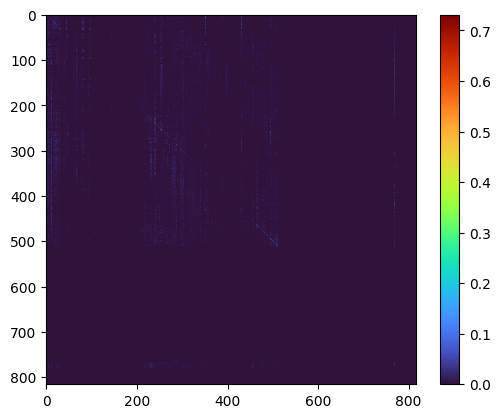

In [114]:
mean_attention = input_attentions[-1].mean(dim=1).squeeze(0).to(float)  # Average over heads
plt.imshow(mean_attention.cpu().numpy(), cmap='turbo')
plt.colorbar()
plt.savefig(f'pi0/{data_index}_{object.replace(" ", "_")}_mean_attention_map_last_layer.png')
mean_attention.max(), mean_attention.min(),input_attentions[-1].shape

In [115]:
mean_attention[774]

tensor([3.4798e-04, 3.5291e-04, 3.2527e-04, 4.9967e-04, 2.1775e-02, 2.8364e-04,
        3.2605e-04, 4.0996e-04, 4.6174e-04, 6.5652e-04, 3.3869e-04, 2.5583e-02,
        1.4424e-03, 2.8995e-04, 1.5925e-03, 1.0780e-03, 3.9687e-03, 4.2698e-04,
        2.3637e-04, 2.1376e-03, 5.5066e-03, 3.7536e-04, 2.2162e-02, 2.7223e-04,
        8.8965e-03, 2.9160e-04, 2.8922e-04, 5.7255e-04, 2.4199e-03, 1.4460e-02,
        2.6853e-04, 1.0145e-04, 1.4219e-03, 2.1061e-03, 8.0423e-04, 4.6105e-04,
        4.2371e-04, 5.4896e-04, 7.9366e-04, 4.6060e-04, 3.3101e-04, 7.0710e-04,
        1.9059e-04, 3.4460e-04, 3.5171e-04, 8.6523e-03, 6.1237e-05, 1.2424e-03,
        1.8444e-04, 8.1526e-05, 7.9788e-05, 7.2820e-05, 3.0209e-04, 2.6221e-04,
        8.0550e-04, 4.8849e-04, 6.7819e-04, 6.1743e-04, 3.6931e-04, 3.4903e-04,
        2.8658e-04, 5.7641e-05, 5.5494e-05, 7.2520e-04, 1.3135e-04, 4.7356e-04,
        2.6935e-04, 7.1918e-04, 2.6586e-04, 2.0841e-04, 2.4023e-04, 2.5358e-04,
        4.6851e-04, 5.3270e-04, 6.2362e-

In [116]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

def generate_attention_heatmap(images, attn_weights,
                               action_token_idx=-1, 
                               image_token_slice=slice(0, 256),
                               layer_idx=-1, 
                               head_idx=None):
    """
    生成attention heatmap并叠加到原始图像上，并圈出最大值位置
    
    Args:
        images: 原始图像列表 [batch_size, channels, height, width] 或 [batch_size, height, width, channels]
        attn_weights: attention权重列表
        action_token_idx: 使用哪个action token看attention
        image_token_slice: image token对应的序列范围
        layer_idx: 使用哪一层的attention权重（默认最后一层）
        head_idx: 使用哪个attention head（默认对所有head取平均）
    """
    
    # 获取指定层的attention权重
    layer_attn = attn_weights[layer_idx].to(float)
    
    # 假设 layer_attn 形状: [batch_size, num_heads, seq_len, seq_len]
    batch_size = layer_attn.shape[0]
    
    heatmaps = []
    
    for batch_idx in range(batch_size):
        # 当前batch的attention
        batch_attn = layer_attn[batch_idx]
        
        # 选择head
        if head_idx is not None:
            head_attn = batch_attn[head_idx]
        else:
            head_attn = batch_attn.mean(dim=0, keepdim=True).squeeze(0)
        
        num_image_tokens = image_token_slice.stop - image_token_slice.start
        
        # 取 action token 对 image tokens 的 attention
        image_attentions = head_attn[action_token_idx, image_token_slice.start:image_token_slice.stop]
        
        # 重塑为2D patch网格
        grid_size = int(np.sqrt(num_image_tokens))
        heatmap_2d = image_attentions.reshape(grid_size, grid_size).cpu().numpy()
        
        # 取当前图像尺寸
        original_img = images[batch_idx]
        
        # 兼容 CHW 和 HWC
        if original_img.ndim == 3 and original_img.shape[0] in [1, 3]:
            # CHW -> HWC
            original_img = np.transpose(original_img, (1, 2, 0))
        
        original_height, original_width = original_img.shape[:2]
        
        # 上采样到原始图像大小
        heatmap_resized = cv2.resize(
            heatmap_2d, 
            (original_width, original_height), 
            interpolation=cv2.INTER_LINEAR
        )
        
        # 归一化到 [0, 1]
        heatmap_normalized = (heatmap_resized - heatmap_resized.min()) / \
                             (heatmap_resized.max() - heatmap_resized.min() + 1e-8)
        
        # 转为彩色 heatmap
        heatmap_colored = cv2.applyColorMap(
            np.uint8(255 * heatmap_normalized), 
            cv2.COLORMAP_JET
        )
        
        # 原图转 uint8
        if original_img.dtype != np.uint8:
            original_img = np.clip(original_img, 0, 255).astype(np.uint8)
        
        # 如果是单通道，转成3通道
        if original_img.ndim == 2:
            original_img = cv2.cvtColor(original_img, cv2.COLOR_GRAY2BGR)
        elif original_img.shape[2] == 1:
            original_img = cv2.cvtColor(original_img, cv2.COLOR_GRAY2BGR)
        
        # 叠加 heatmap 到原图
        alpha = 0.3
        overlay = cv2.addWeighted(
            original_img, 
            1 - alpha, 
            heatmap_colored, 
            alpha, 
            0
        )
        
        # 找最大值位置
        max_y, max_x = np.unravel_index(np.argmax(heatmap_resized), heatmap_resized.shape)
        
        # 在图上圈出最大值
        overlay_with_circle = overlay.copy()
        cv2.circle(
            overlay_with_circle,
            (int(max_x), int(max_y)),
            radius=12,
            color=(0, 255, 0),   # 绿色圆圈
            thickness=2
        )
        
        # 可选：再画一个中心点
        cv2.circle(
            overlay_with_circle,
            (int(max_x), int(max_y)),
            radius=3,
            color=(255, 255, 255),  # 白色中心点
            thickness=-1
        )
        
        heatmaps.append({
            'heatmap': heatmap_resized,
            'overlay': overlay_with_circle,
            'original': original_img,
            'max_point': (int(max_x), int(max_y)),
            'max_value': float(heatmap_resized[max_y, max_x])
        })
    
    return heatmaps


def visualize_attention_heads(
    img_batch,
    attentions,
    action_token_idx,
    image_token_slice,
    layer_idx=-1,
    num_heads=32,
    n_rows=7,
    n_cols=5,
    figsize=(15, 21),
    title=None
):
    """
    Generate and visualize attention heatmaps for each head.

    Args:
        img_batch: np.ndarray, shape [1, H, W, C]
        attentions: list of attention tensors
        action_token_idx: int
        image_token_slice: slice
        layer_idx: int
        num_heads: number of attention heads
        n_rows, n_cols: subplot layout
        figsize: matplotlib figure size
    """

    heatmaps = []

    # 1️⃣ 生成每个 head 的 heatmap
    for head_idx in range(num_heads):
        heatmap = generate_attention_heatmap(
            img_batch,
            attentions,
            action_token_idx=action_token_idx,
            image_token_slice=image_token_slice,
            layer_idx=layer_idx,
            head_idx=head_idx,
            
        )
        heatmaps.append(heatmap)

    # 2️⃣ 画 grid
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = axes.flatten()

    for idx, ax in enumerate(axes):
        if idx < len(heatmaps):
            ax.imshow(heatmaps[idx][0]["overlay"])
            ax.set_title(f"head: {idx},max:{heatmaps[idx][0]['heatmap'].max():.4f}", fontsize=11)
            ax.axis("off")
        else:
            ax.axis("off")

    plt.tight_layout()
    if title is not None:
        plt.savefig(f'{title}.png')
    else:
        plt.show()

(np.float64(0.05451231340385493), np.float64(2.6403631100097025e-05))

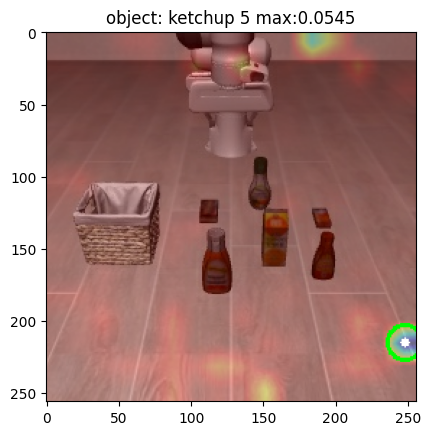

In [117]:
language_idx = 772

'''

0-256 :img1: [16,16]
256-512: img2
512-768: img3
769-816: language tokens[48]


q * k =[b, num_heads, seq_len, seq_len]
773: juice 

observation.language.attention_mask torch.Size([1, 48]) cuda:1
(tensor([[    2, 18075,   908,   573, 10436, 17796,   578,  2040,   665,   575,
            573, 12220,   108,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
              0,     0,     0,     0,     0,     0,     0,     0]],
        device='cuda:1'),
 tensor([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
           True,  True,  True, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False, False, False,
          False, False, False, False, False, False, False, False]],
        device='cuda:1'),
 ['pick up the orange juice and place it in the basket\n'])

1. heatmap visiualization? 
2. add action heatmap:

3. lerobot/pi0_libero_base


'''

img_batch = np.expand_dims(image_pil, axis=0)

heatmap = generate_attention_heatmap(img_batch, input_attentions,
                               action_token_idx=language_idx, 
                               image_token_slice=slice(0, 256),
                         layer_idx=-1, 
                         head_idx=None)

plt.imshow(heatmap[0]['overlay'])
plt.title(
    f"object: {object.replace(' ', '_')} {data_index} "
    f"max:{heatmap[0]['heatmap'].max():.4f}"
)
# plt.colorbar()
plt.savefig(f'pi0/{data_index}_{object.replace(" ", "_")}_heatmap_mean_object_1.png')
heatmap[0]['heatmap'].max(), heatmap[0]['heatmap'].min()

In [118]:
mean_attention[language_idx][0:256].max(), mean_attention[language_idx][0:256].min()

(tensor(0.0563, device='cuda:1', dtype=torch.float64),
 tensor(2.6220e-05, device='cuda:1', dtype=torch.float64))

(np.float64(0.028585250602472634), np.float64(6.16931807542187e-05))

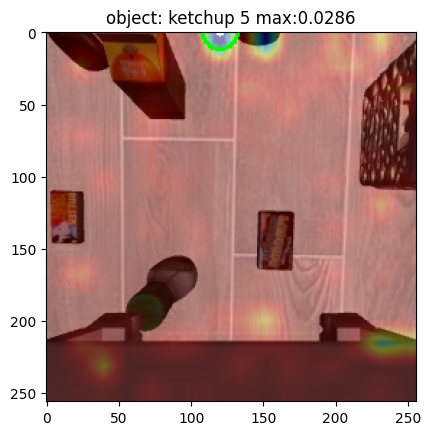

In [119]:
wrist_img_batch = np.expand_dims(wrist_image, axis=0)

heatmap2 = generate_attention_heatmap(wrist_img_batch, input_attentions,
                               action_token_idx=language_idx, 
                               image_token_slice=slice(256, 512),
                         layer_idx=-1, 
                         head_idx=None)

plt.imshow(heatmap2[0]['overlay'])
plt.title(
    f"object: {object.replace(' ', '_')} {data_index} "
    f"max:{heatmap2[0]['heatmap'].max():.4f}"
)
# plt.colorbar()
plt.savefig(f'pi0/{data_index}_{object.replace(" ", "_")}_heatmap_mean_object_2.png')
heatmap2[0]['heatmap'].max(), heatmap2[0]['heatmap'].min()

In [120]:
mean_attention[language_idx][256:512].argmax(), mean_attention[language_idx][256:512].min()

(tensor(7, device='cuda:1'),
 tensor(5.6715e-05, device='cuda:1', dtype=torch.float64))

(np.float64(0.0), np.float64(0.0))

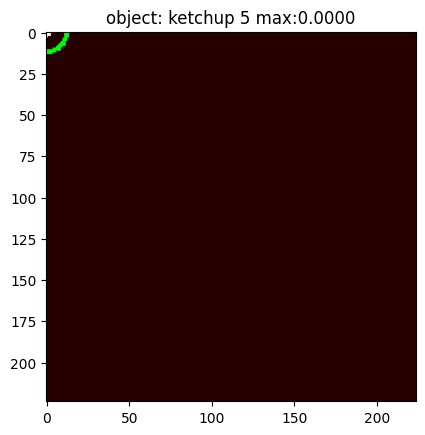

In [121]:
wrist_img_batch = np.expand_dims(wrist_image_np, axis=0)

heatmap3 = generate_attention_heatmap(wrist_img_batch, input_attentions,
                               action_token_idx=language_idx, 
                               image_token_slice=slice(512, 768),
                         layer_idx=-1, 
                         head_idx=None)

plt.imshow(heatmap3[0]['overlay'])
plt.title(
    f"object: {object.replace(' ', '_')} {data_index} "
    f"max:{heatmap3[0]['heatmap'].max():.4f}"
)
# plt.colorbar()
plt.savefig(f'pi0/{data_index}_{object.replace(" ", "_")}_heatmap_mean_object_3.png')
heatmap3[0]['heatmap'].max(), heatmap3[0]['heatmap'].min()

In [122]:
def find_peaks(signal, height=None):
    signal = np.asarray(signal)

    # 找局部最大值
    peaks = np.where(
        (signal[1:-1] > signal[:-2]) &
        (signal[1:-1] > signal[2:])
    )[0] + 1

    # 高度筛选
    if height is not None:
        peaks = peaks[signal[peaks] >= height]

    properties = {
        "peak_heights": signal[peaks]
    }
    return peaks, properties


def compute_attention_heatmap(
    attention_1d,
    grid_size,
    original_image,
    normalize=True,
    alpha=0.3,
):
    """
    输入:
        attention_1d: (num_patches,)
        grid_size: patch grid size (e.g. 16, 24)
        original_image: (H, W, C) or (H, W)

    输出:
        heatmap: (H, W) float32 heatmap
    """
    # 1. patch → grid
    attention_grid = attention_1d.reshape(grid_size, grid_size)

    # 2. resize 到原图大小
    h, w = original_image.shape[:2]
    heatmap = cv2.resize(
        attention_grid,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )
    # 找最大值位置
    max_y, max_x = np.unravel_index(np.argmax(heatmap), heatmap.shape)
    # 3. 归一化（可选）
    if normalize:
        heatmap = (heatmap - heatmap.min()) / \
                  (heatmap.max() - heatmap.min() + 1e-8)
        
    heatmap = cv2.applyColorMap( np.uint8(255 * heatmap), cv2.COLORMAP_JET )    
    overlay = cv2.addWeighted(
        original_image, 
        1 - alpha, 
        heatmap, 
        alpha, 
        0
    )

        
    # 在图上圈出最大值
    overlay_with_circle = overlay.copy()
    cv2.circle(
        overlay_with_circle,
        (int(max_x), int(max_y)),
        radius=12,
        color=(0, 255, 0),   # 绿色圆圈
        thickness=2
    )
    
    # 可选：再画一个中心点
    cv2.circle(
        overlay_with_circle,
        (int(max_x), int(max_y)),
        radius=3,
        color=(255, 255, 255),  # 白色中心点
        thickness=-1
    )
    

    return overlay_with_circle


def plot_mean_attention(
    importance_heatmap,
    object,
    data_index,
    idx,
    max_value=0
):
    plt_title = f'pi0/{data_index}_{object.replace(" ", "_")}_heatmap_mean__{idx}'
    plt.imshow(importance_heatmap, cmap='turbo')
    plt.title(
        f"{object.replace(' ', '_')} {data_index} "
        f"max:{max_value :.4f}"
    )
    # plt.colorbar()
    plt.savefig(f'{plt_title}.png')

def analyze_multi_object_attention(attention_map, token_info,original_image=None, object='', data_index=0,idx =1):
    """
    分析多物体场景下的attention分布
    """
    # 提取action token对图像的attention
    action_to_image = attention_map[
        token_info['action_start']:token_info['action_end'],
        token_info['image_start']:token_info['image_end']
    ]
    
    num_actions = action_to_image.shape[0]
    num_patches = action_to_image.shape[1]
    grid_size = int(np.sqrt(num_patches))
    
    # 计算每个patch被所有action token关注的总强度
    patch_importance = action_to_image.sum(axis=0)
    
    # 重塑为2D网格
    importance_grid = patch_importance.reshape(grid_size, grid_size)
    
    # 计算attention的集中度（使用Gini系数）
    sorted_attention = np.sort(patch_importance)
    n = len(sorted_attention)
    cum_attention = np.cumsum(sorted_attention)
    gini = (n + 1 - 2 * np.sum(cum_attention) / cum_attention[-1]) / n
    
    print(f"Attention Gini系数: {gini:.4f}")
    print(f"Top-5 patches占据总attention的: {sorted_attention[-5:].sum()/sorted_attention.sum()*100:.1f}%")
    
    # 分析多峰值现象
    threshold = np.percentile(patch_importance, 75)

    peaks, properties = find_peaks(
        patch_importance,
        height=threshold
    )
    
    print(f"发现 {len(peaks)} 个attention峰值")

    importance_heatmap = compute_attention_heatmap(
            attention_1d=patch_importance,
            grid_size=grid_size,
            original_image=original_image,
            normalize=True,
            alpha=0.3,
        )
    plot_mean_attention(
        importance_heatmap=importance_heatmap,
        object=object,
        data_index=data_index,
        idx=idx,
        max_value=patch_importance.max()/num_actions
        )
    
    # 可视化
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    

    # # 1. attention热力图
    # im1 = axes[0, 0].imshow(importance_heatmap, cmap='YlOrRd')
    # axes[0, 0].set_title('Overall Attention Heatmap')
    # axes[0, 0].axis('off')
    # plt.colorbar(im1, ax=axes[0, 0])
    
    # # 2. attention分布直方图
    # axes[0, 1].hist(patch_importance, bins=50, alpha=0.7)
    # axes[0, 1].axvline(x=np.median(patch_importance), color='r', 
    #                   linestyle='--', label=f'Median: {np.median(patch_importance):.4f}')
    # axes[0, 1].set_xlabel('Attention Value')
    # axes[0, 1].set_ylabel('Frequency')
    # axes[0, 1].set_title('Attention Distribution')
    # axes[0, 1].legend()
    # axes[0, 1].grid(True)
    
    # 3. 不同action token的关注模式
    # 对action token进行聚类分析
    from sklearn.cluster import KMeans
    kmeans = KMeans(n_clusters=min(4, num_actions), random_state=42)
    clusters = kmeans.fit_predict(action_to_image)
    
    unique_clusters = np.unique(clusters)
    for cluster in unique_clusters:
        
        row = cluster // 2 
        col = cluster % 2
        cluster_indices = np.where(clusters == cluster)[0]
        cluster_attention = action_to_image[cluster_indices].mean(axis=0)

        overlay = compute_attention_heatmap(
            attention_1d=cluster_attention,
            grid_size=grid_size,
            original_image=original_image,
            normalize=True,
            alpha=0.3,
        )

        im = axes[row, col].imshow(overlay, cmap='viridis')
        axes[row, col].set_title(f'{object} {data_index} Cluster {cluster} ({len(cluster_indices)} tokens) max:{cluster_attention.max():.4f}')
        # axes[row, col].axis('off')
        # plt.colorbar(im, ax=axes[row, col])
    
    plt.tight_layout()
    plt.savefig(f'pi0/{data_index}_{object.replace(" ", "_")}_heatmap_action_attention_{idx}.png')
    return fig, gini, len(peaks)

Attention Gini系数: 0.5068
Top-5 patches占据总attention的: 11.5%
发现 45 个attention峰值


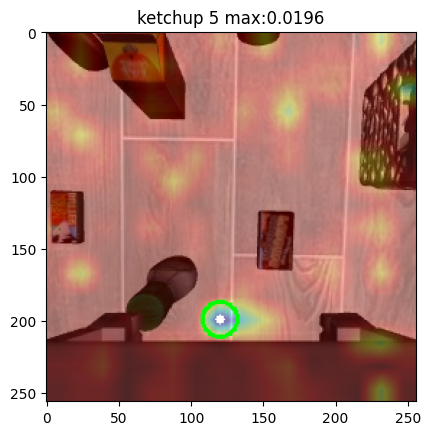

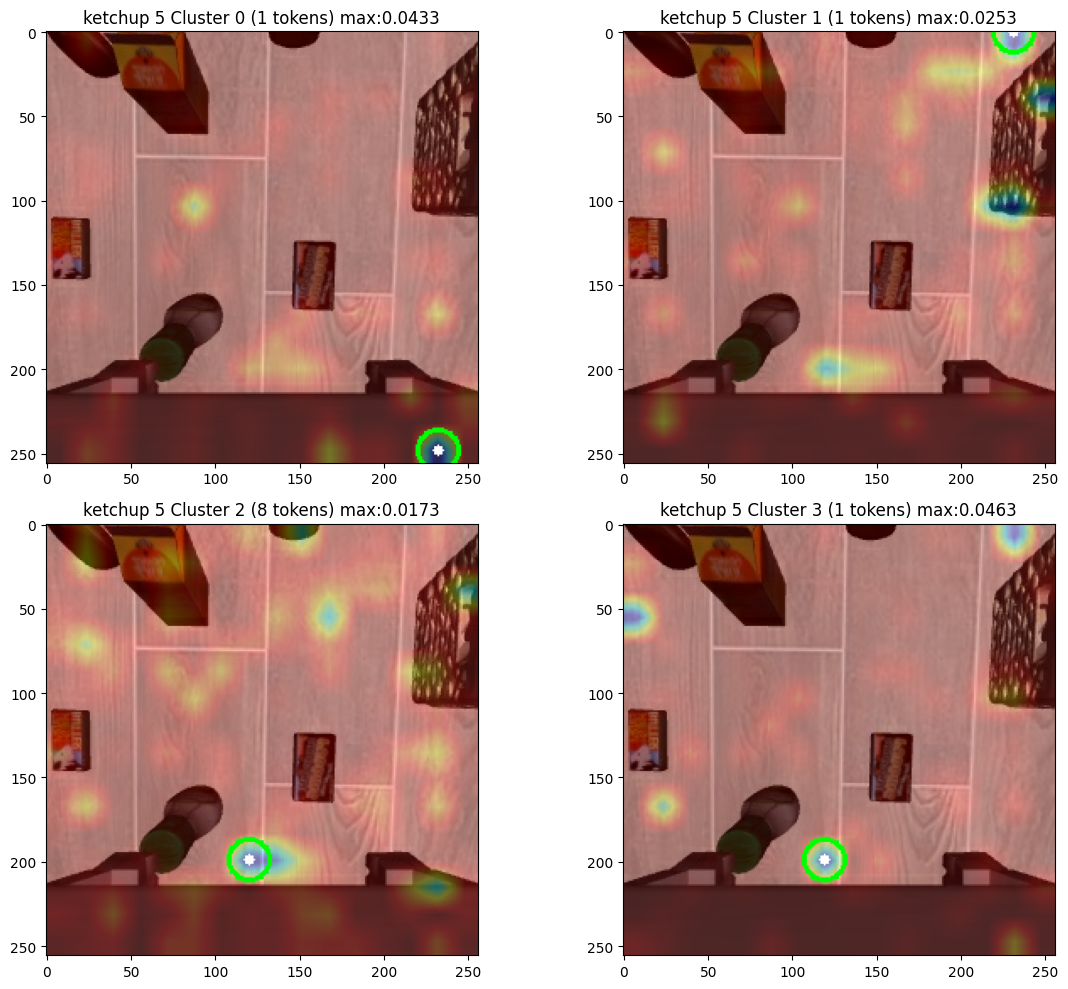

In [123]:
token_info = {
    'image_start': 256,
    'image_end': 512,
    'action_start': 769,
    'action_end': 780,
}
fig, gini, num_peaks = analyze_multi_object_attention(
    mean_attention.cpu().numpy(), token_info,original_image=wrist_image,object=object,data_index=data_index,idx=2
)

Attention Gini系数: 0.6794
Top-5 patches占据总attention的: 26.0%
发现 37 个attention峰值


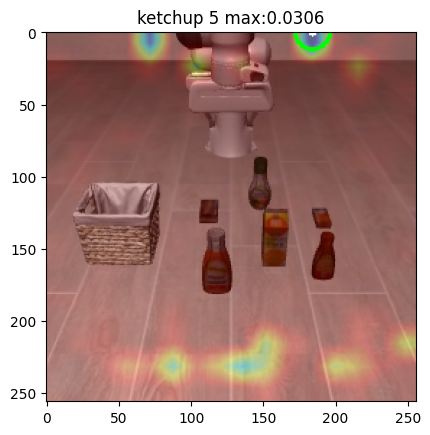

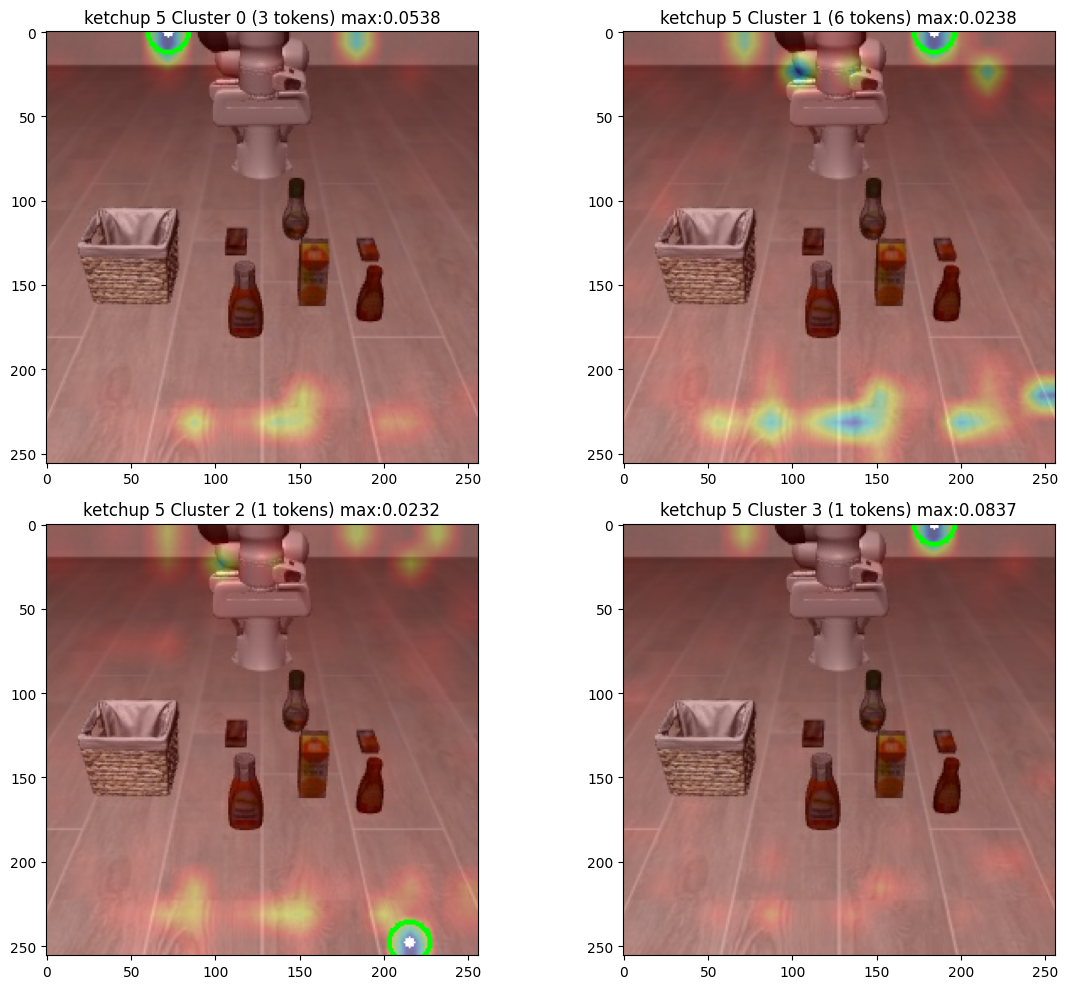

In [124]:
token_info = {
    'image_start': 0,
    'image_end': 256,
    'action_start': 769,
    'action_end': 780,
}
fig, gini, num_peaks = analyze_multi_object_attention(
    mean_attention.cpu().numpy(), token_info,original_image=image_pil,object=object,data_index=data_index,idx=1
)